In [4]:
%pylab inline

nzs=4
import gc
import glob
import fitsio
import numpy as np
import numpy.lib.recfunctions as rfn
import catutil
import matplotlib.cm as cm

Populating the interactive namespace from numpy and matplotlib


In [2]:
cd /lustre/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/

/lustre/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut


# Photo-$z$
## photo-$z$ binning (the bool array for binning for mocks)

In [7]:
if False:
    #pzname='dnnz' #demp/mizuki/dnnz
    pzname='mizuki'
    #pzname='dempz'
    pzDir='catalog_others/'
    outDir='cosmicShear/photoz_mockmask/'
    for fieldname in catutil.field_names:
        fname   =   os.path.join(pzDir,'%s_pz_2.fits' %fieldname)
        data    =   fitsio.read(fname)
        ndArrays=[]
        for iz in range(nzs):
            zmin=   (iz+1)*0.3
            zmax=   (iz+2)*0.3
            mask=   (data['%s_photoz_best' %pzname]>=zmin)&(data['%s_photoz_best' %pzname]<zmax)
            types=[('%s_mask_%sbin' %(pzname,iz),'?')]
            out   =   np.array(mask,dtype=types)
            ndArrays.append(out)
        final=rfn.merge_arrays(ndArrays, flatten=True, usemask=False)
        fitsio.write(os.path.join(outDir,'%s_%s_zmask.fits' %(fieldname,pzname)),final)
        del data,final,mask,out,ndArrays
        gc.collect()

## Stack posterier $P(z \mid z_{\rm best})$

In [ ]:
#pzname='dnnz' #dempz/mizuki/dnnz
pzname='mizuki'
#pzname='dempz'
outDir =   'cosmicShear/photoz_stack/%s/' %pzname
if not os.path.isdir(outDir):
    os.mkdir(outDir)
pzDir=os.path.join('catalog_tracts','XMM_tracts')
pbins= pyfits.getdata(os.path.join(pzDir,'8522_pz_pdf_%s.fits' %pzname),ext=2)['BINS']
nbin=len(pbins)

for fieldname in catutil.field_names:
    print(fieldname)
    outname1=os.path.join(outDir,'%s_stack.fits' %(fieldname))
    if os.path.isfile(outname1):
        poz_ave=pyfits.getdata(outname1)
        continue
    inDir  =   os.path.join('catalog_tracts','%s_tracts' %fieldname) 
    fnames=glob.glob(os.path.join(inDir,'*_pz_pdf_%s.fits' %(pzname)))
    poz_ave=np.zeros((nzs,nbin))
    wAll=np.zeros(nzs)
    for pfname in fnames:
        assert os.path.isfile(pfname)
        pata=pyfits.getdata(pfname)
        
        fname=pfname.split('pz_pdf')[0]+'pz.fits'
        assert os.path.isfile(fname)
        data=pyfits.getdata(fname)
        if pzname=='mizuki':
            mskAdd=np.isfinite(data['mizuki_photoz_best'])
        poz_best=data['dnnz_photoz_best']# fix the best-fit estimation code for binning
        del data,fname
        fname=pfname.split('pz_pdf')[0]+'no_m.fits'
        data=pyfits.getdata(fname)
        if pzname=='mizuki':
            data=data[mskAdd]
            poz_best=poz_best[mskAdd]
            pata=pata[mskAdd]
        for iz in range(nzs):
            zmin=   (iz+1)*0.3
            zmax=   (iz+2)*0.3
            tmp_msk=(poz_best>zmin)&(poz_best<zmax)
            tmp_wA=np.sum(data['i_hsmshaperegauss_derived_weight'][tmp_msk])
            poz_ave[iz]+=np.average(pata['PDF'][tmp_msk],weights=data['i_hsmshaperegauss_derived_weight'][tmp_msk],axis=0)*tmp_wA
            wAll[iz]+=tmp_wA
            del tmp_msk,tmp_wA
        del data,pata
        gc.collect()
    poz_ave=poz_ave/wAll[:,None]
    out=pyfits.HDUList([pyfits.PrimaryHDU(poz_ave),\
        pyfits.BinTableHDU.from_columns([pyfits.Column(name='BINS',array=pbins,format='D')]),\
        pyfits.BinTableHDU.from_columns([pyfits.Column(name='weightAll',array=wAll,format='D')])])
    out.writeto(outname1,overwrite=True)
    del poz_ave,out,outname1,wAll
    gc.collect

XMM


In [ ]:
poz_All=np.zeros((nzs,nbin))
wAll=np.zeros(nzs)
for fieldname in catutil.field_names:
    outname1=os.path.join(outDir,'%s_stack.fits' %(fieldname))
    poz_ave=pyfits.getdata(outname1)
    wSub=pyfits.getdata(outname1,ext=2)['weightAll']
    poz_All=poz_All+poz_ave*wSub[:,None]
    wAll=wAll+wSub
    fig=plt.figure(figsize=(5,12))
    for i in range(nzs):
        ax=fig.add_subplot(4,1,i+1)
        ax.set_title('redshift bin %d' %(i+1),y=1.0, pad=-14)
        ax.plot(pbins,poz_ave[i],color='black',label=pzname)
        ax.set_yscale('log')
        ax.set_xlim(0,6)
        ax.set_ylim(1e-5,1)
        if i==0:
            ax.legend(fontsize=12)
    outname2=os.path.join(outDir,'%s_stack.png' %(fieldname))
    fig.savefig(outname2)
    outname2=os.path.join(outDir,'%s_stack.pdf' %(fieldname))
    fig.savefig(outname2)
    del fig,poz_ave,wSub
    gc.collect()

## Hamana cosmic shear paper

In [ ]:
poz_All=poz_All/wAll[:,None]
fig=plt.figure(figsize=(5,12))
for i in range(nzs):
    ax=fig.add_subplot(4,1,i+1)
    ax.set_title('redshift bin %d' %(i+1),y=1.0, pad=-14)
    ax.plot(pbins,poz_All[i],color='black',label=pzname)
    ax.set_yscale('log')
    ax.set_xlim(0,6)
    ax.set_ylim(1e-5,1)
    if i==0:
        ax.legend(fontsize=12)
outname2=os.path.join(outDir,'All_stack.png')
fig.savefig(outname2)
outname2=os.path.join(outDir,'All_stack.pdf')

fig.savefig(outname2)
del fig,outname2
gc.collect()

## Chiaki cosmic shear paper

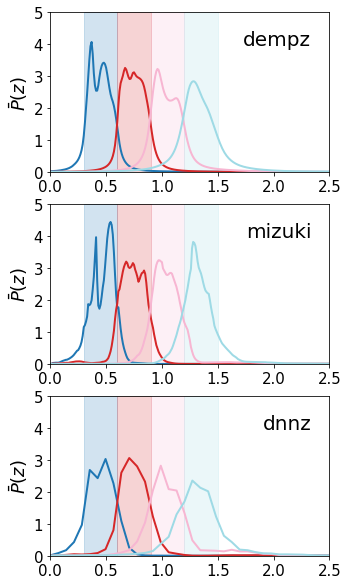

In [21]:
cmap = cm.tab20
norm = Normalize(vmin=0, vmax=nzs-1)
pzList=['dempz','mizuki','dnnz']
fig=plt.figure(figsize=(5,10))
for mm in range(3):
    pzname=pzList[mm]
    pzDir=os.path.join('catalog_tracts','XMM_tracts')
    Dir =   'cosmicShear/photoz_stack/%s/' %pzname
    pbins= pyfits.getdata(os.path.join(pzDir,'8522_pz_pdf_%s.fits' %pzname),ext=2)['BINS']
    nbin=len(pbins)
    ax=fig.add_subplot(3,1,mm+1)
    
    poz_All=np.zeros((nzs,nbin))
    wAll=np.zeros(nzs)
    for fieldname in maputil.field_names:
        outname1=os.path.join(Dir,'%s_stack.fits' %(fieldname))
        poz_ave=pyfits.getdata(outname1)
        wSub=pyfits.getdata(outname1,ext=2)['weightAll']
        poz_All=poz_All+poz_ave*wSub[:,None]
        wAll=wAll+wSub
        del poz_ave,wSub
        gc.collect()
    poz_All=poz_All/wAll[:,None]
    for ip in range(nzs):
        cc=cmap(norm(ip))
        if ip==0:
            ax.plot(pbins,poz_All[0]/np.sum(poz_All[0])/(pbins[1]-pbins[0]),\
                    color=cc,label=pzname)
        else:
            ax.plot(pbins,poz_All[ip]/np.sum(poz_All[ip])/(pbins[1]-pbins[0]),\
                    color=cc)
        plt.axvspan((ip+1)*0.3,(ip+2)*0.3,alpha=0.2, color=cc)

    #ax.set_yscale('log')
    ax.set_xlim(0,2.5)
    ax.set_ylim(0,5.0)
    ax.set_ylabel(r'$\bar{P}(z)$')
    ax.legend(frameon=False,handlelength=0)
outDir =   'cosmicShear/photoz_stack/'
outname2=os.path.join(outDir,'All_stack_ylinear.png')
fig.savefig(outname2)
outname2=os.path.join(outDir,'All_stack_ylinear.pdf')
fig.savefig(outname2)

## Questions:
+ shall we use the same binning scheme as S16A?
+ shall we use dnnz for the binning?
+ some big, bright galaxies do not have mizuki photo-z measurement; therefore, np.isfinite(mizuki_best) is added for the result of mizuki. The question is --- do we need to remove those galaxies in our fiducial binning?